# Minería de Datos — Reducción Dimensional
## Análisis y Comparación de PCA y NMF en Inversión Pública
**Docente:** Soledad Espezúa Llerena  
**Grupo:** Data Hunters (Fernando Torres, Romy Tipacti, Arturo Alvarez)  
**Proyecto:** Obras públicas en ejecución activa del MEF / Invierte.pe (1,978 proyectos)

---

## Introducción

En este informe aplicamos dos técnicas de reducción de dimensionalidad: **PCA** (Análisis de Componentes Principales) y **NMF** (Factorización de Matrices No Negativas).
Trabajamos sobre la base de datos de nuestro proyecto de obras públicas (1,978 proyectos CUI) que limpiamos y preparamos en el Hito 2.

El objetivo es reducir la cantidad de variables continuas para encontrar los factores principales que explican el comportamiento de las obras, evaluar cuál técnica se interpreta mejor en nuestro problema y cuál nos servirá más para hacer clustering en el Hito 3.

In [1]:
# Importamos las librerías para análisis de datos, visualización y reducción dimensional
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, NMF

# Configuración básica para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.float_format", lambda x: "%.4f" % x)

## Carga de la matriz analítica del proyecto

Cargamos el archivo CSV con la matriz analítica final que obtuvimos al terminar el Hito 2.
Esta base tiene 1,978 proyectos de inversión pública en ejecución activa, que son los que tienen datos reales de avance físico en obra y de gasto presupuestal.

In [2]:
# Cargamos la matriz analítica del proyecto
df_proyecto = pd.read_csv("matriz_analitica_final.csv")

print("Dimensiones de la base:", df_proyecto.shape)
display(df_proyecto.head(3))

Dimensiones de la base: (1978, 17)


,codigo_proyecto,nombre_proyecto,nivel_gobierno,departamento,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,flag_gasto_adelantado,tamano_inversion_ord,gob_GOBIERNOS LOCALES,gob_GOBIERNOS REGIONALES
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,GOBIERNO NACIONAL,LIMA,70.2882,100.0000,-29.7118,263517133.5300,185221572.5800,22,8419162.3900,39,65.0000,0,3,0,0
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,GOBIERNO NACIONAL,LIMA,64.6477,100.0000,-35.3523,269114681.5500,173976517.4700,22,7908023.5214,25,37.0000,0,3,0,0
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,GOBIERNOS REGIONALES,ANCASH,36.6074,100.0000,-63.3926,189747493.8600,69461580.6600,22,3157344.5755,27,52.0000,0,3,0,1


## 1. Selección de atributos numéricos

Seleccionamos únicamente las variables numéricas cuantitativas continuas que describen el avance físico, costo presupuestal y tiempo de los proyectos.

**Variables que seleccionamos (9 variables continuas):**
- pct_ejecucion_financiera: porcentaje de gasto ejecutado respecto al costo de la obra.
- avance_fisico_pct: porcentaje de avance físico reportado en la obra.
- brecha_gasto_avance: diferencia entre gasto financiero y avance físico (porcentaje de gasto menos porcentaje de avance físico).
- costo_inversion: costo total actualizado del proyecto en soles.
- gasto_total: monto total devengado acumulado en soles.
- tiempo_maduracion_anios: años que lleva el proyecto desde que empezó su ejecución.
- gasto_anual_promedio: promedio de gasto por año en soles.
- n_registros_presupuesto: cantidad de años en los que el proyecto recibió presupuesto.
- n_contratos: número de contratos o procesos de selección registrados.

**Variables que no incluimos y por qué:**
- Excluimos el codigo_proyecto (CUI) porque es solo un identificador o código de seguimiento.
- Excluimos los textos como nombre_proyecto, departamento y nivel_gobierno porque son variables cualitativas.
- Excluimos las variables binarias y dummies (como flag_gasto_adelantado y las columnas de gobierno) porque los algoritmos PCA y NMF asumen variables cuantitativas continuas. Si incluimos variables de ceros y unos, se distorsiona el cálculo de las distancias, la covarianza y la varianza explicada.


In [3]:
# Definimos la lista de variables numéricas analíticas
variables = [
    "pct_ejecucion_financiera",
    "avance_fisico_pct",
    "brecha_gasto_avance",
    "costo_inversion",
    "gasto_total",
    "tiempo_maduracion_anios",
    "gasto_anual_promedio",
    "n_registros_presupuesto",
    "n_contratos"
]

# Creamos la matriz X solo con estas variables
X = df_proyecto[variables].copy()

print("Tamaño de la matriz X:", X.shape)
display(X.describe().T[["min", "mean", "50%", "max", "std"]])

Tamaño de la matriz X: (1978, 9)


,min,mean,50%,max,std
pct_ejecucion_financiera,0.5807,52.6420,45.4493,749.2497,43.9529
avance_fisico_pct,0.0000,75.5636,89.5900,100.0000,29.5409
brecha_gasto_avance,-97.6688,-22.9216,-30.4735,649.2497,48.8317
costo_inversion,15362.5000,41983868.2814,6630171.9370,12075451952.7400,292478188.6032
gasto_total,14560.6000,13094726.1748,3001958.3850,1837811051.6900,54723797.7267
tiempo_maduracion_anios,1.0000,10.9424,10.0000,22.0000,3.3749
gasto_anual_promedio,2080.0857,1056448.9410,281561.5905,141370080.8992,4059342.1000
n_registros_presupuesto,1.0000,13.9808,13.0000,87.0000,7.7524
n_contratos,1.0000,174.3670,103.0000,4592.0000,271.1015


## 2. Aplicamos PCA

### Estandarización con StandardScaler
En la tabla anterior vemos que las variables tienen escalas muy diferentes:
- El costo de inversión y el gasto total están en millones de soles (con desviaciones estándar de más de 30 millones).
- El avance físico y el porcentaje de ejecución van de 0 a 100.
- El tiempo de maduración y los contratos son números pequeños (de 1 a 15).

Si aplicamos PCA directamente sin estandarizar, la primera componente solo se fijaría en el costo de inversión debido a su magnitud numérica significativamente superior.
Por esta razón, aplicamos StandardScaler para que todas las variables tengan media 0 y desviación estándar 1, permitiendo una comparación equilibrada de su variabilidad.

In [4]:
# Estandarizamos los datos
scaler_std = StandardScaler()
X_std = scaler_std.fit_transform(X)

# Verificamos que la media sea 0 y la varianza 1
print("Medias después de estandarizar (deben ser cercanas a 0):", np.round(X_std.mean(axis=0), 2))
print("Desviación estándar (debe ser 1):", np.round(X_std.std(axis=0), 2))

# Aplicamos PCA
pca = PCA()
Z = pca.fit_transform(X_std)

print("Dimensiones de la matriz transformada Z:", Z.shape)

Medias después de estandarizar (deben ser cercanas a 0): [ 0.  0. -0.  0. -0.  0.  0.  0. -0.]
Desviación estándar (debe ser 1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]
Dimensiones de la matriz transformada Z: (1978, 9)


### Varianza explicada y número de componentes (criterio del 80%)

Calculamos la varianza explicada por cada componente y la varianza acumulada para ver cuántas componentes necesitamos para conservar aproximadamente el 80%.

In [5]:
# Creamos la tabla de varianza explicada individual y acumulada
tabla_varianza = pd.DataFrame({
    "Componente": [f"Z{j+1}" for j in range(len(variables))],
    "Autovalor": pca.explained_variance_,
    "Varianza (%)": pca.explained_variance_ratio_ * 100,
    "Varianza acumulada (%)": np.cumsum(pca.explained_variance_ratio_) * 100
})

print("Tabla de varianza explicada:")
display(tabla_varianza)

# Vemos en qué componente superamos el 80%
k_80 = int(np.argmax(tabla_varianza["Varianza acumulada (%)"] >= 80) + 1)
print(f"Para conservar aproximadamente el 80% de la varianza necesitamos {k_80} componentes.")
print(f"Con {k_80} componentes alcanzamos {tabla_varianza.loc[k_80-1, 'Varianza acumulada (%)']:.2f}% de la varianza acumulada.")

Tabla de varianza explicada:


,Componente,Autovalor,Varianza (%),Varianza acumulada (%)
0,Z1,3.0332,33.6857,33.6857
1,Z2,1.9722,21.9020,55.5877
2,Z3,1.4381,15.9709,71.5587
3,Z4,1.1207,12.4457,84.0044
4,Z5,0.9517,10.5695,94.5739
5,Z6,0.3522,3.9112,98.4851
6,Z7,0.1224,1.3595,99.8446
7,Z8,0.0140,0.1554,100.0000
8,Z9,0.0000,0.0000,100.0000


Para conservar aproximadamente el 80% de la varianza necesitamos 4 componentes.
Con 4 componentes alcanzamos 84.00% de la varianza acumulada.


### Gráfico de varianza explicada (Scree plot)

Hacemos el gráfico de barras con la varianza individual de cada componente y la línea de la varianza acumulada marcando el corte del 80%.

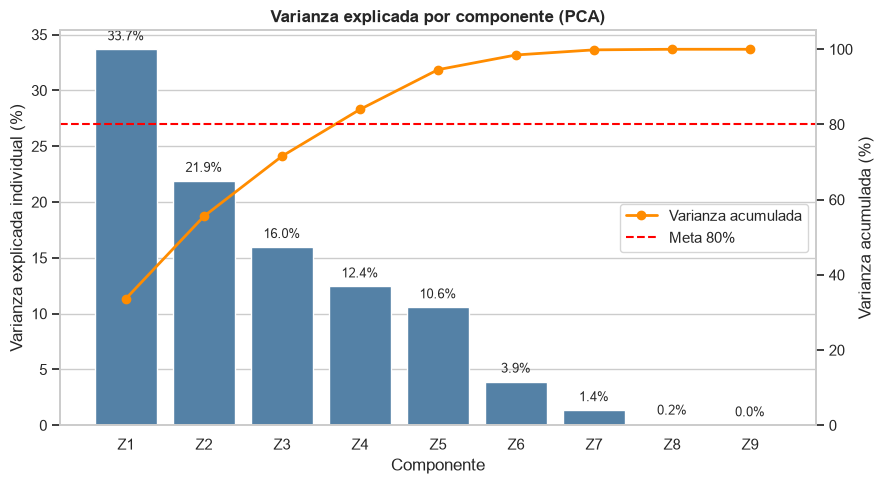

In [6]:
fig, ax1 = plt.subplots(figsize=(9, 5))

# Barras de varianza individual
sns.barplot(
    data=tabla_varianza,
    x="Componente",
    y="Varianza (%)",
    color="steelblue",
    ax=ax1
)
ax1.set_ylabel("Varianza explicada individual (%)")
ax1.set_xlabel("Componente")
ax1.set_title("Varianza explicada por componente (PCA)", fontsize=12, fontweight="bold")

# Línea de varianza acumulada
ax2 = ax1.twinx()
ax2.plot(
    range(len(tabla_varianza)),
    tabla_varianza["Varianza acumulada (%)"],
    color="darkorange",
    marker="o",
    linewidth=2,
    label="Varianza acumulada"
)
ax2.axhline(y=80, color="red", linestyle="--", label="Meta 80%")
ax2.set_ylabel("Varianza acumulada (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)
ax2.legend(loc="center right")

# Mostramos el porcentaje sobre cada barra
for i, row in tabla_varianza.iterrows():
    ax1.text(i, row["Varianza (%)"] + 0.8, f"{row['Varianza (%)']:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

### Interpretación del gráfico de varianza explicada:

En este gráfico podemos observar claramente dos cosas importantes:
1. **Concentración de la información en las primeras componentes:** Las dos primeras barras (Z1 con 33.7% y Z2 con 21.9%) concentran juntas el **55.6%** de toda la variabilidad de las 9 variables originales.
2. **Corte en 4 componentes:** La línea naranja de varianza acumulada cruza la línea roja del 80% justo en la cuarta componente (Z4), alcanzando un **84.0% acumulado**. A partir de Z5, cada barra aporta menos del 10% y el aporte va cayendo rápidamente. Por lo tanto, elegir 4 componentes nos permite simplificar el problema a menos de la mitad de dimensiones sin perder información relevante.

### Interpretación de Z1 y Z2 a partir de las direcciones de proyección (loadings)

Armamos la tabla de direcciones de proyección (matriz P) para ver los pesos de cada variable original en las componentes Z1 y Z2.

Pesos de las variables originales en las componentes:


,Z1,Z2,Z3,Z4
pct_ejecucion_financiera,-0.1016,0.5703,0.1521,0.4996
avance_fisico_pct,-0.0677,-0.2158,-0.3451,0.7646
brecha_gasto_avance,-0.0505,0.6439,0.3457,-0.0128
costo_inversion,0.5276,0.1158,-0.1804,-0.0048
gasto_total,0.5494,0.1245,-0.1229,0.0354
tiempo_maduracion_anios,0.1913,-0.2682,0.5190,0.3489
gasto_anual_promedio,0.5443,0.1426,-0.1583,-0.0047
n_registros_presupuesto,0.2558,-0.2914,0.5441,0.1223
n_contratos,0.0630,-0.0863,0.3166,-0.1662


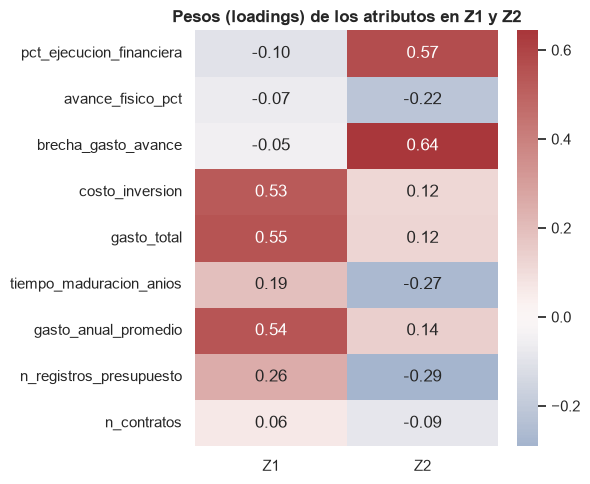

In [7]:
# Matriz de pesos P
P = pd.DataFrame(
    pca.components_.T,
    index=variables,
    columns=[f"Z{j+1}" for j in range(len(variables))]
)

print("Pesos de las variables originales en las componentes:")
display(P[["Z1", "Z2", "Z3", "Z4"]])

# Mapa de calor de los pesos en Z1 y Z2
plt.figure(figsize=(6, 5))
sns.heatmap(
    P[["Z1", "Z2"]],
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0
)
plt.title("Pesos (loadings) de los atributos en Z1 y Z2", fontweight="bold")
plt.tight_layout()
plt.show()

### ¿Cómo interpretamos Z1 y Z2 a partir del mapa de calor?

Mirando los valores y colores del mapa de calor de pesos (loadings):

1. **Interpretación de Z1 (Escala y magnitud del dinero):**
   - En la primera columna (Z1), las variables con colores rojos más intensos y pesos más altos son:
     - gasto_total (+0.55)
     - gasto_anual_promedio (+0.54)
     - costo_inversion (+0.53)
   - Todas estas variables miden montos de dinero del proyecto. Por eso, **Z1 representa el tamaño o escala financiera de la obra**. Los proyectos con valor alto en Z1 son megaproyectos y obras con gran presupuesto; los valores bajos o negativos son obras pequeñas locales.

2. **Interpretación de Z2 (Descalce financiero vs físico / Alerta de gasto adelantado):**
   - En la segunda columna (Z2), las variables con mayor peso positivo (en rojo) son:
     - brecha_gasto_avance (+0.64)
     - pct_ejecucion_financiera (+0.57)
   - Mientras que las variables con peso negativo (en azul) son:
     - n_registros_presupuesto (-0.29)
     - tiempo_maduracion_anios (-0.27)
     - avance_fisico_pct (-0.22)
   - Por eso, **Z2 representa el descalce entre el dinero gastado y el avance físico**. Un valor alto en Z2 identifica obras donde el gasto financiero va muy adelantado respecto al avance real en obra (proyectos de riesgo o con sobrecosto). Valores negativos indican proyectos donde el avance físico marcha bien en relación al gasto.

### Visualizamos los proyectos en el plano Z1 y Z2

Graficamos los 1,978 proyectos en las dos primeras componentes.
Para entender mejor el gráfico, coloreamos los puntos según si el proyecto tiene alerta de gasto adelantado (brecha mayor al 15%), tal como definimos en el Hito 2.

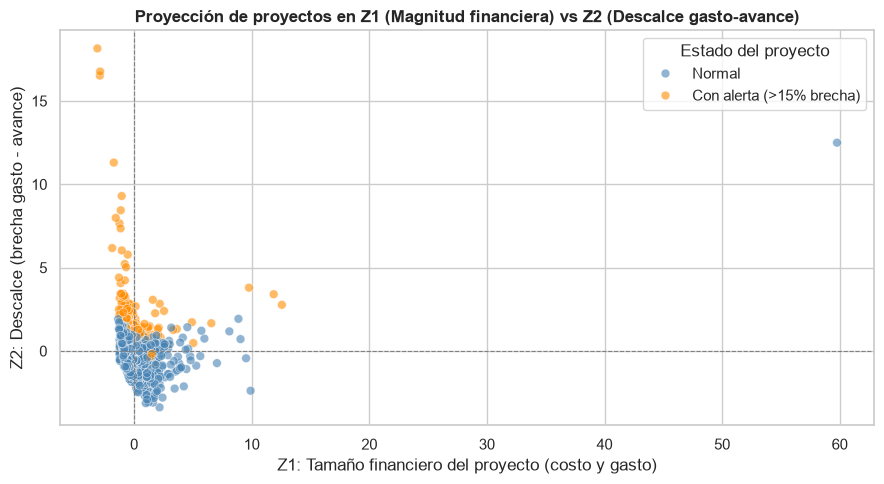

In [8]:
# Preparamos los datos para graficar
df_pca_plot = pd.DataFrame({
    "Z1": Z[:, 0],
    "Z2": Z[:, 1],
    "alerta": df_proyecto["flag_gasto_adelantado"].map({1: "Con alerta (>15% brecha)", 0: "Normal"})
})

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_pca_plot,
    x="Z1",
    y="Z2",
    hue="alerta",
    palette={"Normal": "steelblue", "Con alerta (>15% brecha)": "darkorange"},
    alpha=0.6,
    s=40
)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)

plt.title("Proyección de proyectos en Z1 (Magnitud financiera) vs Z2 (Descalce gasto-avance)", fontweight="bold")
plt.xlabel("Z1: Tamaño financiero del proyecto (costo y gasto)")
plt.ylabel("Z2: Descalce (brecha gasto - avance)")
plt.legend(title="Estado del proyecto")
plt.tight_layout()
plt.show()

### Interpretación del gráfico de dispersión PCA (Z1 vs Z2):

Al observar la distribución de los proyectos en el plano, notamos tres patrones muy claros de negocio:
1. **Separación vertical de las alertas en Z2:** Los puntos naranja (proyectos con alerta por descalce mayor al 15%) se ubican casi en su totalidad en la mitad superior del gráfico (con valores positivos de Z2 mayores a 1 o 2). Esto comprueba que la componente Z2 separa muy bien a los proyectos riesgosos de los proyectos con ejecución normal (puntos azules en la parte inferior).
2. **Distribución del tamaño de los proyectos en Z1:** La gran masa de proyectos se agrupa a la izquierda (Z1 entre -1 y 2), lo que refleja que la mayoría de obras en el Perú son de tamaño pequeño o mediano. Conforme nos movemos hacia la derecha en Z1 (valores mayores a 4), encontramos proyectos aislados que corresponden a los megaproyectos de inversión pública.
3. **Identificación de casos críticos (cuadrante superior derecho):** Las obras ubicadas arriba a la derecha son las más peligrosas para el Estado: son megaproyectos que manejan presupuestos enormes y que a la vez presentan un grave descalce entre el dinero desembolsado y la obra construida.

## 3. Aplicamos NMF sobre los mismos atributos

### ¿Por qué no usamos StandardScaler en NMF?
StandardScaler centra las variables en cero y genera números negativos.
El algoritmo NMF impone la restricción matemática estricta de que todos los datos sean no negativos (mayores o iguales a cero, $X \ge 0$).
Por este motivo, para NMF usamos MinMaxScaler, que transforma y acota cada variable exactamente en el rango de 0 a 1.

In [9]:
# Escalamos con MinMaxScaler
scaler_minmax = MinMaxScaler()
X_minmax = scaler_minmax.fit_transform(X)

print("Valores mínimos después de MinMaxScaler:", X_minmax.min())
print("Valores máximos después de MinMaxScaler:", X_minmax.max())

# Aplicamos NMF configurando 2 componentes para la descomposición
nmf = NMF(
    n_components=2,
    init="random",
    random_state=1,
    max_iter=2000
)

# W representa los proyectos en los 2 factores
W = nmf.fit_transform(X_minmax)

# H representa el peso de cada variable original en los factores
H = pd.DataFrame(
    nmf.components_,
    index=["Factor 1", "Factor 2"],
    columns=variables
)

print("Dimensiones de W:", W.shape)
print("Dimensiones de H:", H.shape)
print(f"Error de reconstrucción: {nmf.reconstruction_err_:.4f}")

Valores mínimos después de MinMaxScaler: 0.0
Valores máximos después de MinMaxScaler: 1.0
Dimensiones de W: (1978, 2)
Dimensiones de H: (2, 9)
Error de reconstrucción: 6.1848


### Matriz H: composición de los factores

Mostramos la matriz H en una tabla y con un mapa de calor para ver qué atributos tienen más peso en cada factor.

Valores de la matriz H:


,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos
Factor 1,0.0748,0.0436,0.3398,0.0179,0.0359,1.7228,0.0342,0.6527,0.1246
Factor 2,0.1057,1.6110,0.0209,0.0000,0.0000,0.1534,0.0000,0.0000,0.0150


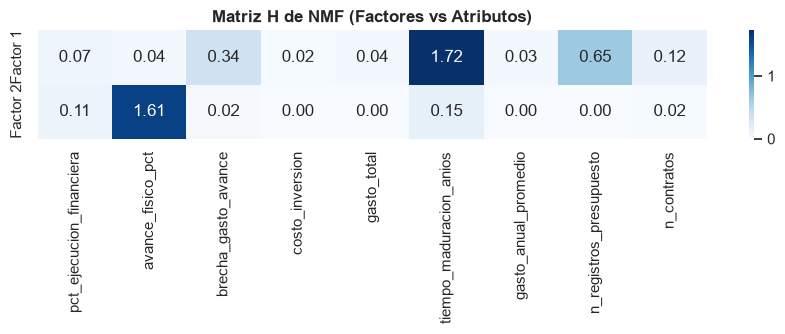

In [10]:
print("Valores de la matriz H:")
display(H)

plt.figure(figsize=(9, 3.5))
sns.heatmap(
    H,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)
plt.title("Matriz H de NMF (Factores vs Atributos)", fontweight="bold")
plt.tight_layout()
plt.show()

### Interpretación de los factores de NMF a partir de la matriz H

Mirando los valores más altos de cada fila de H:

1. **Factor 1:**
   - Las variables con mayor peso son:
     - tiempo_maduracion_anios (1.72)
     - n_registros_presupuesto (0.65)
     - brecha_gasto_avance (0.34)
   - Este factor representa la **antigüedad y tiempo de maduración del proyecto** (obras que llevan muchos años en ejecución y que arrastran historial presupuestal).

2. **Factor 2:**
   - La variable con mayor peso con mucha diferencia es:
     - avance_fisico_pct (1.61)
   - Y luego pct_ejecucion_financiera (0.11).
   - Este factor representa el **avance o culminación física de la obra**. Los proyectos con valor alto en este factor son obras que ya tienen gran avance físico en terreno.

**Detalle importante sobre el dinero en NMF:**
En NMF, las variables de costo_inversion y gasto_total quedaron con pesos casi en 0. Esto pasa porque al usar MinMaxScaler, la gran mayoría de obras son de montos pequeños o medianos y quedan aplastadas cerca a 0 por culpa de unos pocos megaproyectos que tienen costos gigantescos.

### Visualizamos los proyectos en el espacio de NMF (W1 vs W2)

Graficamos los proyectos usando las dos columnas de la matriz W, coloreando también por la alerta de gasto adelantado.

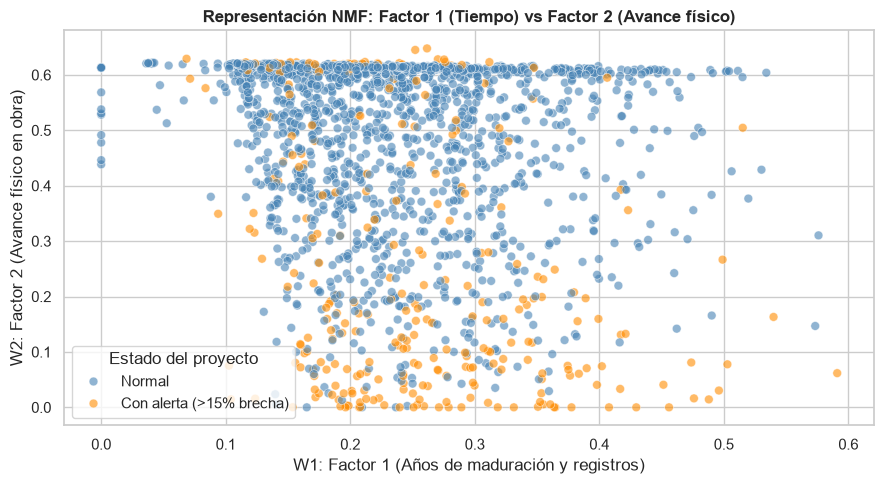

In [11]:
df_nmf_plot = pd.DataFrame({
    "W1": W[:, 0],
    "W2": W[:, 1],
    "alerta": df_proyecto["flag_gasto_adelantado"].map({1: "Con alerta (>15% brecha)", 0: "Normal"})
})

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_nmf_plot,
    x="W1",
    y="W2",
    hue="alerta",
    palette={"Normal": "steelblue", "Con alerta (>15% brecha)": "darkorange"},
    alpha=0.6,
    s=40
)
plt.title("Representación NMF: Factor 1 (Tiempo) vs Factor 2 (Avance físico)", fontweight="bold")
plt.xlabel("W1: Factor 1 (Años de maduración y registros)")
plt.ylabel("W2: Factor 2 (Avance físico en obra)")
plt.legend(title="Estado del proyecto")
plt.tight_layout()
plt.show()

### Interpretación del gráfico de NMF (W1 vs W2):

Al observar el gráfico de dispersión de los dos factores de NMF vemos una forma completamente diferente a PCA:
1. **Forma en 'L' desde el origen (0, 0):** Como NMF no permite valores negativos, todos los puntos se originan en la esquina inferior izquierda (cero) y se dispersan a lo largo de los dos ejes positivos.
2. **Eje vertical (W2 - Avance físico):** Los proyectos que están arriba tienen un avance físico alto (obras casi terminadas).
3. **Eje horizontal (W1 - Tiempo de maduración):** Los proyectos que se extienden hacia la derecha son obras antiguas que llevan muchos años acumulando registros de presupuesto.
4. **Comportamiento de las alertas:** Los puntos naranja (con alerta de gasto adelantado) se extienden principalmente a lo largo del eje horizontal W1 (obras longevas con problemas) y se mantienen en la parte baja de W2 (obras con poco avance físico). Sin embargo, a diferencia de PCA, en este gráfico no podemos distinguir cuáles obras son megaproyectos y cuáles son pequeñas porque el factor dinero quedó comprimido en cero.

## 4. Comparación entre PCA y NMF

A continuación, realizamos la evaluación comparativa entre ambas técnicas de reducción dimensional:

### ¿PCA y NMF resaltan los mismos atributos?
No resaltan los mismos atributos.
- PCA resalta en su primera componente las variables de dinero (gasto total, costo de inversión y gasto anual) y en la segunda componente resalta la brecha entre gasto y avance físico.
- NMF, en cambio, resalta en el Factor 1 los años de maduración y en el Factor 2 el avance físico, dejando los costos y gastos con pesos casi en cero.
Esto se debe a cómo se escala la data: StandardScaler mantiene la variación de los montos monetarios centrados en cero, mientras que MinMaxScaler comprime los costos de la mayoría de obras cerca de cero por la presencia de megaproyectos muy grandes.

### ¿Cuál de las dos representaciones resulta más fácil de interpretar en el contexto del proyecto?
La representación de PCA resulta más fácil y útil para nuestro proyecto.
En PCA, el eje horizontal (Z1) nos dice claramente qué tan grande es la obra a nivel financiero, y el eje vertical (Z2) nos dice directamente si el proyecto tiene descalce entre lo que gasta y lo que avanza en obra. Esto nos permite ubicar de forma inmediata en la parte superior derecha a los megaproyectos con alto riesgo de gasto adelantado.
En NMF, la escala del dinero se pierde y la brecha se mezcla con los años de maduración, por lo que es más difícil ver directamente las alertas de gasto.

### ¿Cuál consideran inicialmente más útil para continuar posteriormente con clustering? Justificación
Consideramos que PCA es más útil para la etapa de clustering por tres razones:
1. Las componentes de PCA son ortogonales (no están correlacionadas entre sí). Esto evita que variables muy relacionadas como costo de inversión y gasto total pesen el doble al calcular distancias en K-Means.
2. Con 4 componentes conservamos el 84% de toda la información original, manteniendo tanto el tamaño de la obra como el descalce y el tiempo.
3. Como PCA trabaja con datos estandarizados, no sufre el problema de compresión que tuvo MinMaxScaler en NMF, lo que permite que el clustering diferencie mejor entre obras pequeñas, medianas y grandes.

## 5. Guardado de las representaciones obtenidas

Guardamos las matrices transformadas Z (de PCA) y W (de NMF) en archivos CSV, manteniendo el codigo_proyecto y las variables de negocio para poder utilizarlas en la siguiente etapa de clustering del Hito 3.

In [12]:
# 1. Guardamos la matriz Z de PCA (con las 4 componentes que explican el 84%)
df_Z = pd.DataFrame(
    Z[:, :k_80],
    columns=[f"Z{j+1}" for j in range(k_80)]
)
# Agregamos identificador y variables de negocio
df_Z.insert(0, "codigo_proyecto", df_proyecto["codigo_proyecto"].values)
df_Z.insert(1, "nombre_proyecto", df_proyecto["nombre_proyecto"].values)
df_Z.insert(2, "nivel_gobierno", df_proyecto["nivel_gobierno"].values)
df_Z.insert(3, "flag_gasto_adelantado", df_proyecto["flag_gasto_adelantado"].values)

df_Z.to_csv("Z_pca_proyecto.csv", index=False)
print("Matriz Z guardada exitosamente en 'Z_pca_proyecto.csv':", df_Z.shape)

# 2. Guardamos la matriz W de NMF (con los 2 factores)
df_W = pd.DataFrame(
    W,
    columns=["W1_Maduracion", "W2_Avance_Fisico"]
)
df_W.insert(0, "codigo_proyecto", df_proyecto["codigo_proyecto"].values)
df_W.insert(1, "nivel_gobierno", df_proyecto["nivel_gobierno"].values)
df_W.insert(2, "flag_gasto_adelantado", df_proyecto["flag_gasto_adelantado"].values)

df_W.to_csv("W_nmf_proyecto.csv", index=False)
print("Matriz W guardada exitosamente en 'W_nmf_proyecto.csv':", df_W.shape)

print("\nPrimeras filas de Z (PCA):")
display(df_Z.head(3))

print("\nPrimeras filas de W (NMF):")
display(df_W.head(3))

Matriz Z guardada exitosamente en 'Z_pca_proyecto.csv': (1978, 8)
Matriz W guardada exitosamente en 'W_nmf_proyecto.csv': (1978, 5)

Primeras filas de Z (PCA):


,codigo_proyecto,nombre_proyecto,nivel_gobierno,flag_gasto_adelantado,Z1,Z2,Z3,Z4
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,GOBIERNO NACIONAL,0,4.4533,-1.0856,2.2465,2.5395
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,GOBIERNO NACIONAL,0,3.8323,-0.7393,1.2133,2.2663
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,GOBIERNOS REGIONALES,0,2.1656,-1.9893,1.5446,1.9165



Primeras filas de W (NMF):


,codigo_proyecto,nivel_gobierno,flag_gasto_adelantado,W1_Maduracion,W2_Avance_Fisico
0,2002060,GOBIERNO NACIONAL,0,0.5341,0.6038
1,2002210,GOBIERNO NACIONAL,0,0.5025,0.6077
2,2002604,GOBIERNOS REGIONALES,0,0.5017,0.6060


## Conclusión grupal 

1. Aplicamos reducción dimensional sobre las 9 variables continuas de 1,978 proyectos del proyecto, logrando con PCA retener el 84.00% de la varianza total con 4 componentes.
2. En PCA, Z1 representa la magnitud del dinero (gasto y costo), mientras que Z2 mide directamente el descalce entre gasto financiero y avance físico de la obra.
3. En NMF, los factores representaron el tiempo de maduración (W1) y el avance físico (W2), pero la escala del dinero se perdió por el escalamiento con MinMaxScaler.
4. Concluimos que PCA es la técnica más adecuada para clustering porque sus componentes ortogonales eliminan la redundancia entre variables de dinero.
5. Además, la proyección de PCA permite identificar con facilidad en el plano a los megaproyectos que tienen alto gasto sin avance físico correspondiente.